In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

Dataset Loading and Initial Exploration

In [9]:
# Load dataset
dataset = pd.read_csv("studentscores.csv")

# Preview dataset
dataset.head(), dataset.shape

(   Hours  Scores
 0    2.5      21
 1    5.1      47
 2    3.2      27
 3    8.5      75
 4    3.5      30,
 (25, 2))

Train–Test Data Split

In [10]:
# Split features and labels
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, 1].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

X_train.shape, X_test.shape

((18, 1), (7, 1))

In [11]:
# Convert data to float32 for TensorFlow
X_train_tf = X_train.astype(np.float32)
y_train_tf = y_train.astype(np.float32)

# Define model parameters
W = tf.Variable(0.0)
b = tf.Variable(0.0)

# Define linear model
def linear_model(x):
    return W * x + b

# Define loss (MSE)
def loss_fn(y_true, y_pred):
    return tf.reduce_mean(tf.square(y_true - y_pred))

# Optimizer
optimizer = tf.optimizers.SGD(learning_rate=0.01)

# Training loop
epochs = 500
for epoch in range(epochs):
    with tf.GradientTape() as tape:
        y_pred = linear_model(X_train_tf)
        loss = loss_fn(y_train_tf, y_pred)
    dW, db = tape.gradient(loss, [W, b])
    optimizer.apply_gradients(zip([dW, db], [W, b]))

W.numpy(), b.numpy(), loss.numpy()

(np.float32(1.6480932), np.float32(45.827858), np.float32(651.1469))

Linear Regression using TensorFlow (Manual Implementation)

In [12]:
# Fix shapes to (n,1)
X_train_tf = X_train.astype(np.float32)
y_train_tf = y_train.reshape(-1, 1).astype(np.float32)

# Reset parameters
W = tf.Variable(0.0)
b = tf.Variable(0.0)

def linear_model(x):
    return W * x + b

def loss_fn(y_true, y_pred):
    return tf.reduce_mean(tf.square(y_true - y_pred))

optimizer = tf.optimizers.SGD(learning_rate=0.01)

epochs = 1000
for epoch in range(epochs):
    with tf.GradientTape() as tape:
        y_pred = linear_model(X_train_tf)
        loss = loss_fn(y_train_tf, y_pred)
    dW, db = tape.gradient(loss, [W, b])
    optimizer.apply_gradients(zip([dW, db], [W, b]))

float(W.numpy()), float(b.numpy()), float(loss.numpy())

(9.944071769714355, 1.916462779045105, 32.55040740966797)

In [13]:
X_test_tf = X_test.astype(np.float32)
y_test_tf = y_test.reshape(-1, 1).astype(np.float32)

y_test_pred_tf = linear_model(X_test_tf)
test_loss_tf = loss_fn(y_test_tf, y_test_pred_tf)

float(test_loss_tf.numpy())

20.34286117553711

TensorFlow Model Prediction Visualization

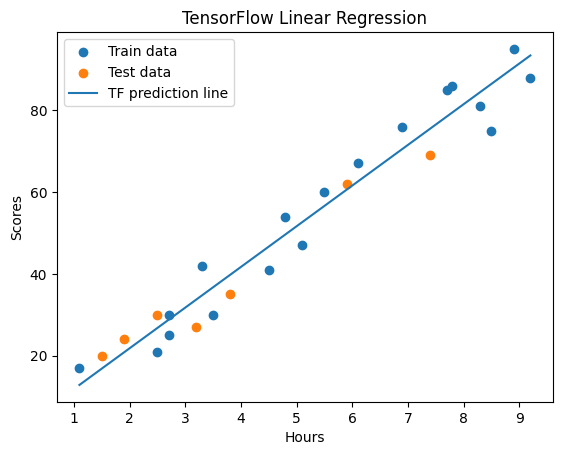

In [14]:
plt.figure()
plt.scatter(X_train, y_train, label="Train data")
plt.scatter(X_test, y_test, label="Test data")

# Line for TF model (use sorted X for a clean line)
X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1).astype(np.float32)
y_line = linear_model(X_line).numpy()

plt.plot(X_line, y_line, label="TF prediction line")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.title("TensorFlow Linear Regression")
plt.legend()
plt.show()

Linear Regression using Scikit-learn

In [15]:
sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

y_pred_sk = sk_model.predict(X_test)

mse_sk = np.mean((y_test - y_pred_sk) ** 2)

sk_model.coef_[0], sk_model.intercept_, mse_sk

(np.float64(9.941678339488096),
 np.float64(1.932204253151646),
 np.float64(20.33292367497997))

Scikit-learn Model Prediction Visualization

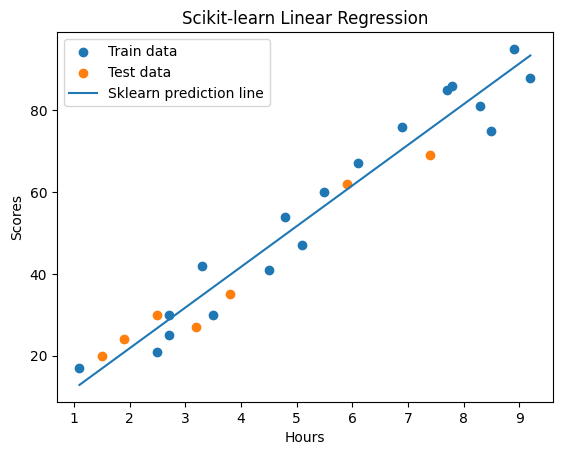

In [16]:
plt.figure()
plt.scatter(X_train, y_train, label="Train data")
plt.scatter(X_test, y_test, label="Test data")

X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line_sk = sk_model.predict(X_line)

plt.plot(X_line, y_line_sk, label="Sklearn prediction line")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.title("Scikit-learn Linear Regression")
plt.legend()
plt.show()

Linear Regression using Keras (Baseline Model)

In [17]:
# Keras model (1 Dense unit = linear regression)
keras_model = Sequential([
    Dense(1, input_shape=(1,))
])

keras_model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01),
                    loss="mse")

history = keras_model.fit(X_train, y_train, epochs=500, verbose=0)

# Evaluate on test set
mse_keras = keras_model.evaluate(X_test, y_test, verbose=0)

mse_keras

c:\Users\hasan\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


20.408004760742188

Keras Model Prediction Visualization

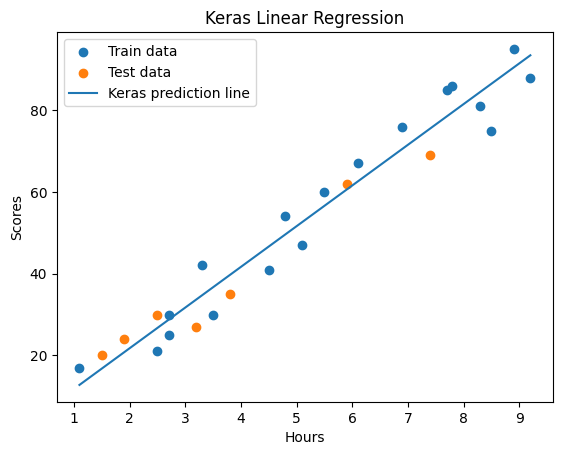

In [18]:
plt.figure()
plt.scatter(X_train, y_train, label="Train data")
plt.scatter(X_test, y_test, label="Test data")

X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line_keras = keras_model.predict(X_line, verbose=0)

plt.plot(X_line, y_line_keras, label="Keras prediction line")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.title("Keras Linear Regression")
plt.legend()
plt.show()

Model Performance Comparison (Test MSE) 

In [19]:
results = pd.DataFrame({
    "Method": ["TensorFlow (manual)", "Scikit-learn", "Keras"],
    "Test MSE": [test_loss_tf.numpy(), mse_sk, mse_keras]
})
results

,Method,Test MSE
0,TensorFlow (manual),20.342861
1,Scikit-learn,20.332924
2,Keras,20.408005


Improved Keras Model (Task 1-3)

In [20]:
# Improved Keras model
keras_model_v2 = Sequential([
    Dense(16, activation="relu", input_shape=(1,)),
    Dense(1)
])

keras_model_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse"
)

history_v2 = keras_model_v2.fit(
    X_train, y_train,
    epochs=1000,
    verbose=0
)

# Evaluate improved model
mse_keras_v2 = keras_model_v2.evaluate(X_test, y_test, verbose=0)
mse_keras_v2

c:\Users\hasan\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


19.934444427490234

In [21]:
extra_results = pd.DataFrame([
    {"Model": "Keras v1", "Architecture": "Dense(1)", "Optimizer": "SGD(lr=0.01)", "Epochs": 500, "Test MSE": mse_keras},
    {"Model": "Keras v2", "Architecture": "Dense(16,relu)->Dense(1)", "Optimizer": "Adam(lr=0.01)", "Epochs": 1000, "Test MSE": mse_keras_v2},
])
extra_results

,Model,Architecture,Optimizer,Epochs,Test MSE
0,Keras v1,Dense(1),SGD(lr=0.01),500,20.408005
1,Keras v2,"Dense(16,relu)->Dense(1)",Adam(lr=0.01),1000,19.934444


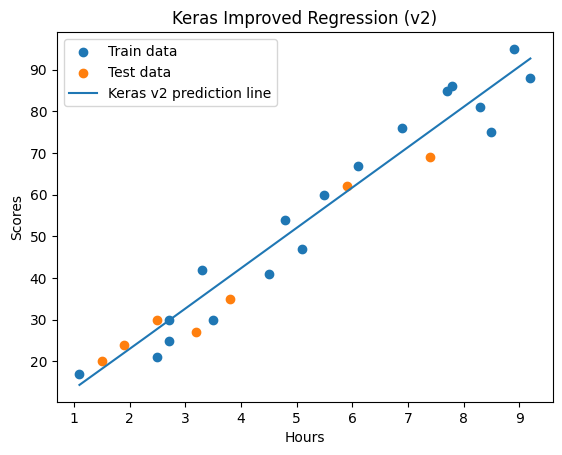

In [22]:
plt.figure()
plt.scatter(X_train, y_train, label="Train data")
plt.scatter(X_test, y_test, label="Test data")

X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line_keras_v2 = keras_model_v2.predict(X_line, verbose=0)

plt.plot(X_line, y_line_keras_v2, label="Keras v2 prediction line")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.title("Keras Improved Regression (v2)")
plt.legend()
plt.show()

Sample Prediction Comparison Across Models

In [23]:
sample_hours = np.array([[2.0], [5.0], [9.0]], dtype=np.float32)

pred_tf = linear_model(sample_hours).numpy().reshape(-1)
pred_sk = sk_model.predict(sample_hours).reshape(-1)
pred_k1 = keras_model.predict(sample_hours, verbose=0).reshape(-1)
pred_k2 = keras_model_v2.predict(sample_hours, verbose=0).reshape(-1)

pred_table = pd.DataFrame({
    "Hours": sample_hours.reshape(-1),
    "TF_pred": pred_tf,
    "Sklearn_pred": pred_sk,
    "Keras_v1_pred": pred_k1,
    "Keras_v2_pred": pred_k2
})
pred_table

,Hours,TF_pred,Sklearn_pred,Keras_v1_pred,Keras_v2_pred
0,2.0,21.804605,21.815561,21.736280,22.982798
1,5.0,51.636822,51.640596,51.613289,52.019203
2,9.0,91.413109,91.407309,91.449295,90.761002
